In [10]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Download HDFC Bank and Nifty 50 data (auto_adjust=True handles splits/dividends)
df = yf.download("HDFCBANK.NS", start="2016-01-01", end="2025-12-31", auto_adjust=True, progress=False)
bench = yf.download("^NSEI", start="2016-01-01", end="2025-12-31", auto_adjust=True, progress=False)

# 2. Fix column alignment cleanly
if isinstance(df.columns, pd.MultiIndex):
    df = df.xs("HDFCBANK.NS", axis=1, level=1)
if isinstance(bench.columns, pd.MultiIndex):
    bench = bench.xs("^NSEI", axis=1, level=1)

# 3. Remove missing values and reorder columns neatly
df = df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()
bench = bench[['Close']].dropna()

# Check that columns and numbers align properly
display(df.head())

Price,Open,High,Low,Close,Volume
Date,,,,,
2016-01-01,244.785855,246.561135,243.372411,246.221909,3195076
2016-01-04,245.147751,245.147751,241.551943,242.094711,5187536
2016-01-05,242.026840,243.067157,240.025409,240.262878,3160872
2016-01-06,238.962493,243.508123,238.962493,241.325760,4165536
2016-01-07,239.742712,240.828248,237.390736,238.860718,6055428


In [11]:
# 1. Calculate 20-Day Average and Z-Score
df['SMA_20'] = df['Close'].rolling(20).mean()  # Simple Moving Average
df['STD_20'] = df['Close'].rolling(20).std()   # Standard Deviation
df['Z_Score'] = (df['Close'] - df['SMA_20']) / df['STD_20']
df = df.dropna()  #Removes Top 19 values with NAN

# 2. Simple Backtest Function
def backtest(data):  # data=dataframe table
    cash = 100000.0
    shares = 0
    entry_price = 0.0
    cost = 0.002  # 0.2% transaction cost

    equity = []  # Equity=Cash+(Shares*Today's Closing Price)
    trades = []

    for i in range(len(data) - 1):
        today = data.iloc[i]
        tomorrow = data.iloc[i + 1]

        # Adding Values in Equity list
        equity.append({'Date': data.index[i], 'Equity': cash + shares * today['Close']})

        # BUY RULE: Stock drops 2 standard deviations below 20-day average (Z < -2)
        if shares == 0 and today['Z_Score'] < -2.0:
            buy_price = tomorrow['Open'] * (1 + cost)
            shares = int(cash // buy_price)
            cash -= shares * buy_price
            entry_price = buy_price
            entry_date = data.index[i + 1]

        # SELL RULE: Stock returns to average (Z >= 0) OR 5% Stop-Loss hit
        elif shares > 0:
            loss_pct = (today['Close'] - entry_price) / entry_price
            if today['Z_Score'] >= 0.0 or loss_pct <= -0.05:
                sell_price = tomorrow['Open'] * (1 - cost)
                cash += shares * sell_price
                ret = ((sell_price - entry_price) / entry_price) * 100

                trades.append({
                    'Buy_Date': entry_date.strftime('%Y-%m-%d'),
                    'Sell_Date': data.index[i + 1].strftime('%Y-%m-%d'),
                    'Buy_Price': round(entry_price, 2),
                    'Sell_Price': round(sell_price, 2),
                    'Return_%': round(ret, 2)
                })
                shares = 0

    equity.append({'Date': data.index[-1], 'Equity': cash + shares * data.iloc[-1]['Close']})
    return pd.DataFrame(equity).set_index('Date'), pd.DataFrame(trades)

# Split into Development (2016-2021) and Unseen Test (2022-2025)
dev_df = df[df.index < "2022-01-01"]
test_df = df[df.index >= "2022-01-01"]

eq_dev, trades_dev = backtest(dev_df)
eq_test, trades_test = backtest(test_df)

print("Test Period Trade Log:")
display(trades_test)

Test Period Trade Log:


,Buy_Date,Sell_Date,Buy_Price,Sell_Price,Return_%
0,2022-02-25,2022-03-07,675.10,615.69,-8.80
1,2022-03-08,2022-03-15,610.52,674.06,10.41
2,2022-04-20,2022-05-26,635.01,634.02,-0.16
3,2022-09-27,2022-10-18,679.37,688.77,1.38
4,2023-01-11,2023-01-19,743.66,773.31,3.99
5,2023-03-16,2023-03-31,729.93,753.75,3.26
6,2023-05-08,2023-05-16,775.46,798.80,3.01
7,2023-10-26,2023-11-16,715.39,721.35,0.83
8,2024-01-18,2024-02-09,716.71,665.18,-7.19
9,2024-05-09,2024-05-24,707.57,720.45,1.82


In [13]:
def get_metrics(eq, trades, bench_df):
    # 1. Align Benchmark (Nifty 50)
    b = bench_df['Close'].reindex(eq.index).ffill()

    # 2. Returns
    cum_ret = ((eq['Equity'].iloc[-1] / eq['Equity'].iloc[0]) - 1) * 100
    # Cumulative Return =(Final Equity/Starting Equity -1)*100

    b_ret = ((b.iloc[-1] / b.iloc[0]) - 1) * 100  #Cumulative return for NIFTY 50 Benchmark
    years = len(eq) / 252
    ann_ret = (((eq['Equity'].iloc[-1] / eq['Equity'].iloc[0]) ** (1 / years)) - 1) * 100
    #Compound Annual Growth Rate=(Final/Initial)^(1/years)-1
    # Used to compare returns for a Training 6 year Period to testing 4 Year Period

    # 3. Maximum Drawdown
    peak = eq['Equity'].cummax()  #Cumulative Maximum
    max_dd = (((eq['Equity'] - peak) / peak) * 100).min() # deepest percentage drop from an all-time high

    # 4. Trade Statistics
    wins = trades[trades['Return_%'] > 0]['Return_%']
    losses = trades[trades['Return_%'] <= 0]['Return_%']
    win_rate = (len(wins) / len(trades)) * 100 if len(trades) > 0 else 0

    return {
        'Cumulative Return (%)': round(cum_ret, 2),
        'Annualized Return (%)': round(ann_ret, 2),
        'Benchmark Return (%)': round(b_ret, 2),
        'Max Drawdown (%)': round(max_dd, 2),
        'Total Trades': len(trades),
        'Win Rate (%)': round(win_rate, 2),
        'Avg Win (%)': round(wins.mean(), 2) if len(wins) > 0 else 0,
        'Avg Loss (%)': round(losses.mean(), 2) if len(losses) > 0 else 0
    }

# Display side-by-side comparison table
results_table = pd.DataFrame({
    'Development (2016-2021)': get_metrics(eq_dev, trades_dev, bench),
    'Test Period (2022-2025)': get_metrics(eq_test, trades_test, bench)
})

display(results_table)

,Development (2016-2021),Test Period (2022-2025)
Cumulative Return (%),-19.36,4.42
Annualized Return (%),-3.64,1.11
Benchmark Return (%),129.44,47.16
Max Drawdown (%),-46.73,-12.21
Total Trades,21.00,13.00
Win Rate (%),66.67,69.23
Avg Win (%),3.18,2.97
Avg Loss (%),-9.00,-5.23


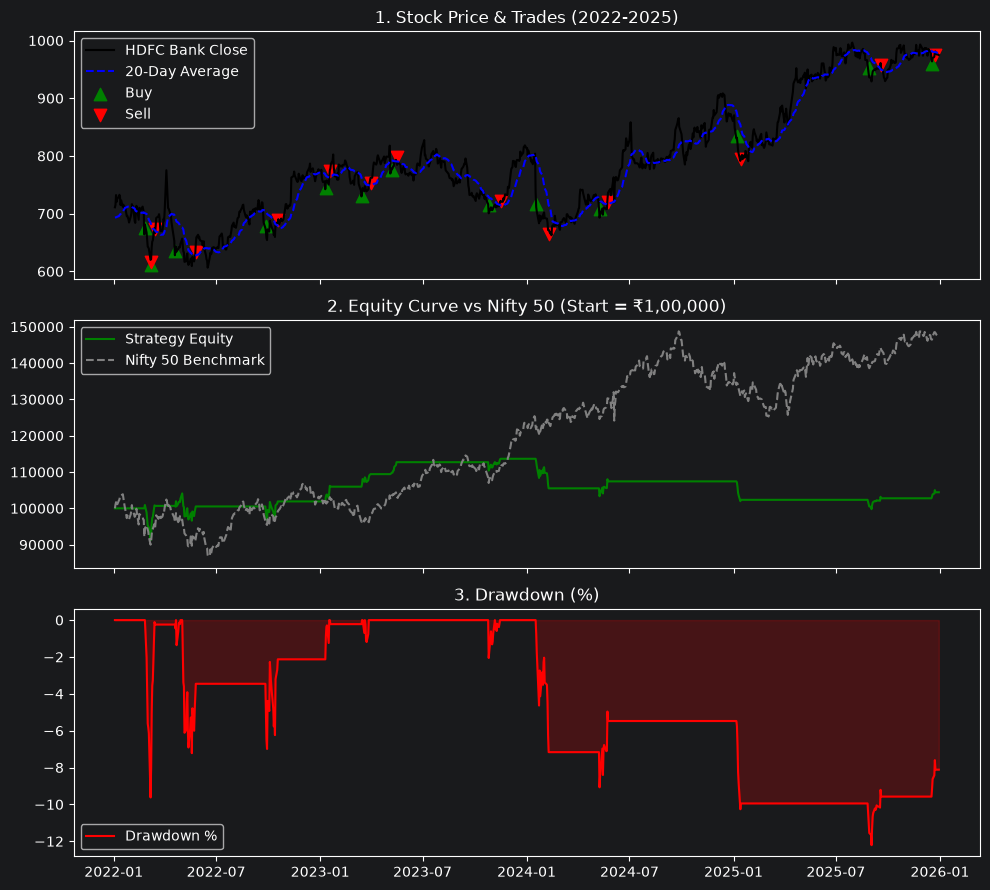

In [14]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
# sharex=true --> locks all three horizontal axes (dates) together i.e same timeline

# 1. Price Chart + Buy/Sell Markers
ax1.plot(test_df.index, test_df['Close'], label='HDFC Bank Close', color='black')
ax1.plot(test_df.index, test_df['SMA_20'], label='20-Day Average', color='blue', linestyle='--')
ax1.scatter(pd.to_datetime(trades_test['Buy_Date']), trades_test['Buy_Price'], color='green', marker='^', s=80, label='Buy')
ax1.scatter(pd.to_datetime(trades_test['Sell_Date']), trades_test['Sell_Price'], color='red', marker='v', s=80, label='Sell')
ax1.set_title("1. Stock Price & Trades (2022-2025)")
ax1.legend()

# 2. Equity Curve vs Nifty 50
b_test = bench['Close'].reindex(eq_test.index).ffill()
b_curve = (b_test / b_test.iloc[0]) * 100000
ax2.plot(eq_test.index, eq_test['Equity'], label='Strategy Equity', color='green')
ax2.plot(b_curve.index, b_curve, label='Nifty 50 Benchmark', color='gray', linestyle='--')
ax2.set_title("2. Equity Curve vs Nifty 50 (Start = ₹1,00,000)")
ax2.legend()

# 3. Drawdown Chart
peak = eq_test['Equity'].cummax()
dd = ((eq_test['Equity'] - peak) / peak) * 100
ax3.plot(dd.index, dd, color='red', label='Drawdown %')
ax3.fill_between(dd.index, dd, 0, color='red', alpha=0.2)
ax3.set_title("3. Drawdown (%)")
ax3.legend()

plt.tight_layout()
plt.show()